# Analisis RTH & PM2.5 Kota Surabaya — Notebook Analisis + Draft Naskah (final)
**Catatan penting sebelum dipakai**
1. Notebook ini **belum pernah dijalankan** oleh penyusunnya (hanya dicek sintaks). Jalankan sel 1 → 4 berurutan, lalu isi placeholder `{...}` di naskah dari output.
   **Data diambil langsung dari Open-Meteo saat sel 1 dijalankan** (butuh internet; tidak bergantung pada hasil run sebelumnya). Cache per tahun disimpan di folder `data_openmeteo/`. Angka bisa sedikit berbeda dari run lama (tahun berjalan bertambah hari, dan model dapat memperbarui nilai); **perbarui angka PM2.5 di naskah sesuai output sel 1.**
2. **Angka taman & jalur hijau:** 1.673,93 ha (5,0%), bukan 1.674,01.
3. **PM2.5 = estimasi model CAMS (Open-Meteo), satu titik grid, belum divalidasi stasiun.** ISPU resmi 2022-2024 mencatat 0 hari "Tidak Sehat".
4. Bagian C **tidak** mengklaim "% efisiensi RTH menurunkan PM2.5": RTH hanya bergerak 22,00 → 22,06% (2022-2025), sehingga hubungan RTH→PM2.5 tidak teridentifikasi dari data ini.
5. Atribusi wajib: *Weather data by Open-Meteo.com* (CC BY 4.0).

In [ ]:
# @title 1. Setup & ambil data langsung dari Open-Meteo (tanpa membaca hasil run lama)
# pip install pandas numpy scikit-learn statsmodels matplotlib seaborn requests
import time, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from datetime import date, timedelta
from pathlib import Path

# ---------------- Konfigurasi ----------------
LAT, LON = -7.2575, 112.7521      # pusat kota (perkiraan); satu titik grid model
MULAI = date(2023, 1, 1)           # hasil uji sebelumnya: PM2.5 Open-Meteo tersedia mulai 2023 (2022 kosong)
HARI_INI = date.today()
FORCE_REFRESH = False              # True = unduh ulang semua tahun (tahun berjalan selalu diunduh ulang)
DATA_DIR = Path("data_openmeteo"); DATA_DIR.mkdir(exist_ok=True)   # cache per tahun
CLEAN = Path("hasil_analisis");    CLEAN.mkdir(exist_ok=True)      # tempat output (klaster_harian.csv)

URL_AQ = "https://air-quality-api.open-meteo.com/v1/air-quality"
URL_CU = "https://archive-api.open-meteo.com/v1/archive"
AQ_HOURLY = "pm2_5,pm10,nitrogen_dioxide,ozone"
CU_DAILY = "temperature_2m_mean,precipitation_sum,wind_speed_10m_max"

def ambil_json(url, params, coba=4):
    # GET dengan retry; None bila gagal
    for i in range(coba):
        try:
            r = requests.get(url, params=params, timeout=120)
            if r.ok:
                js = r.json()
                if js.get("error"):
                    print("   API error:", js.get("reason"))
                    return None
                return js
            print(f"   HTTP {r.status_code}: {r.text[:120]}")
            if r.status_code < 500 and r.status_code != 429:
                return None
        except requests.RequestException as e:
            print("   koneksi gagal:", str(e)[:80])
        time.sleep(2 * (i + 1))
    return None

def aq_tahun(th):
    # PM2.5 dkk per jam untuk satu tahun (cache; tahun berjalan selalu diunduh ulang)
    f = DATA_DIR / f"aq_jam_{th}.csv"
    if f.exists() and not FORCE_REFRESH and th < HARI_INI.year:
        print(f"[AQ {th}] dari cache")
        return pd.read_csv(f, parse_dates=["time"])
    print(f"[AQ {th}] unduh ...")
    js = ambil_json(URL_AQ, {"latitude": LAT, "longitude": LON, "hourly": AQ_HOURLY,
                             "start_date": date(th, 1, 1).isoformat(),
                             "end_date": min(date(th, 12, 31), HARI_INI).isoformat(),
                             "timezone": "Asia/Jakarta"})
    if not js or "hourly" not in js:
        return pd.DataFrame()
    d = pd.DataFrame(js["hourly"]); d["time"] = pd.to_datetime(d["time"])
    d.to_csv(f, index=False)
    return d

def cu_tahun(th):
    # Cuaca harian (arsip punya jeda beberapa hari -> akhir = hari ini - 7)
    a, b = date(th, 1, 1), min(date(th, 12, 31), HARI_INI - timedelta(days=7))
    if a > b:
        return pd.DataFrame()
    f = DATA_DIR / f"cuaca_{th}.csv"
    if f.exists() and not FORCE_REFRESH and th < HARI_INI.year:
        print(f"[Cuaca {th}] dari cache")
        return pd.read_csv(f)
    print(f"[Cuaca {th}] unduh ...")
    js = ambil_json(URL_CU, {"latitude": LAT, "longitude": LON, "start_date": a.isoformat(),
                             "end_date": b.isoformat(), "daily": CU_DAILY, "timezone": "Asia/Jakarta"})
    if not js or "daily" not in js:
        return pd.DataFrame()
    d = pd.DataFrame(js["daily"])
    d.to_csv(f, index=False)
    return d

tahun = range(MULAI.year, HARI_INI.year + 1)
aq_list = [x for x in (aq_tahun(t) for t in tahun) if not x.empty]
cu_list = [x for x in (cu_tahun(t) for t in tahun) if not x.empty]
if not aq_list or not cu_list:
    raise RuntimeError("Gagal mengambil data Open-Meteo (cek koneksi internet, lalu jalankan ulang sel ini).")

# ---- Agregasi harian: PM2.5 rata-rata, hanya hari dengan >= 18 jam terisi
aq_jam = pd.concat(aq_list, ignore_index=True)
aq_jam["tanggal"] = aq_jam["time"].dt.normalize()
aq = (aq_jam.groupby("tanggal")
      .agg(pm2_5_mean=("pm2_5", "mean"), jam_pm25_terisi=("pm2_5", "count")).reset_index())
aq = aq[aq["jam_pm25_terisi"] >= 18]

cu = pd.concat(cu_list, ignore_index=True)
cu["tanggal"] = pd.to_datetime(cu["time"])

# ---- Gabung -> df utama
df = (aq[["tanggal", "pm2_5_mean"]]
      .merge(cu[["tanggal", "temperature_2m_mean", "precipitation_sum", "wind_speed_10m_max"]],
             on="tanggal", how="inner")
      .rename(columns={"pm2_5_mean": "pm25", "temperature_2m_mean": "suhu",
                       "precipitation_sum": "hujan", "wind_speed_10m_max": "angin"})
      .drop_duplicates("tanggal").dropna().sort_values("tanggal").reset_index(drop=True))
print(f"\n{len(df)} hari | {df.tanggal.min():%d %b %Y} - {df.tanggal.max():%d %b %Y}")
print(f"PM2.5 rata-rata = {df.pm25.mean():.2f} µg/m³ | hari > 15 = {(df.pm25 > 15).sum()} "
      f"({(df.pm25 > 15).mean() * 100:.1f}%) | hari > 55 = {(df.pm25 > 55).sum()}")
print("Atribusi: Weather data by Open-Meteo.com (CC BY 4.0)")

[AQ 2023] unduh ...
[AQ 2024] unduh ...
[AQ 2025] unduh ...
[AQ 2026] unduh ...
[Cuaca 2023] unduh ...
[Cuaca 2024] unduh ...
[Cuaca 2025] unduh ...
[Cuaca 2026] unduh ...

1400 hari | 01 Jan 2023 - 31 Oct 2026
PM2.5 rata-rata = 37.83 µg/m³ | hari > 15 = 1352 (96.6%) | hari > 55 = 238
Atribusi: Weather data by Open-Meteo.com (CC BY 4.0)


K=2 | Silhouette = 0.3743 | Inertia (WCSS) = 3298.4
K=3 | Silhouette = 0.3374 | Inertia (WCSS) = 2589.5
K=4 | Silhouette = 0.2762 | Inertia (WCSS) = 2116.7
K=5 | Silhouette = 0.2661 | Inertia (WCSS) = 1858.4
K=6 | Silhouette = 0.2734 | Inertia (WCSS) = 1639.6

>>> K optimal (silhouette tertinggi): K = 2
Catatan: silhouette sering memilih K kecil (mis. K=2, pemisahan musim). Itu sah, tapi lihat juga elbow.


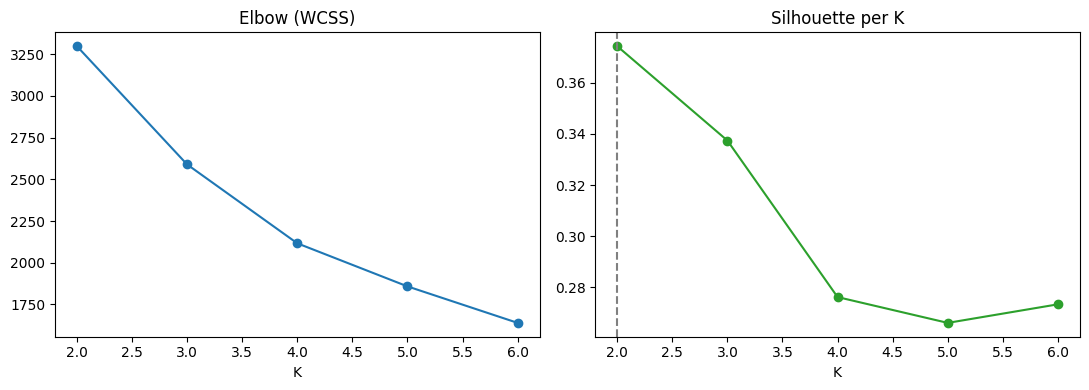


Ringkasan (mean) tiap klaster:
                             n_hari   pm25   suhu  hujan_mm  angin  pct_hari_gt15  pct_hari_gt55  pct_hari
profil                                                                                                    
Klaster 1 (PM2.5 terendah)      775  30.29  28.64      0.53  18.01          93.94           6.06      55.4
Klaster 2 (PM2.5 tertinggi)     625  47.19  27.23     10.05  12.50          99.84          30.56      44.6

Komposisi bulan per klaster (% hari klaster jatuh pada bulan tsb):
tanggal                        1     2     3     4     5     6     7     8     9     10   11    12
profil                                                                                            
Klaster 1 (PM2.5 terendah)    2.0   1.0   3.0   6.0  10.0  13.0  15.0  15.0  15.0  14.0  5.0   2.0
Klaster 2 (PM2.5 tertinggi)  17.0  17.0  16.0  12.0   8.0   3.0   1.0   1.0   0.0   3.0  9.0  13.0


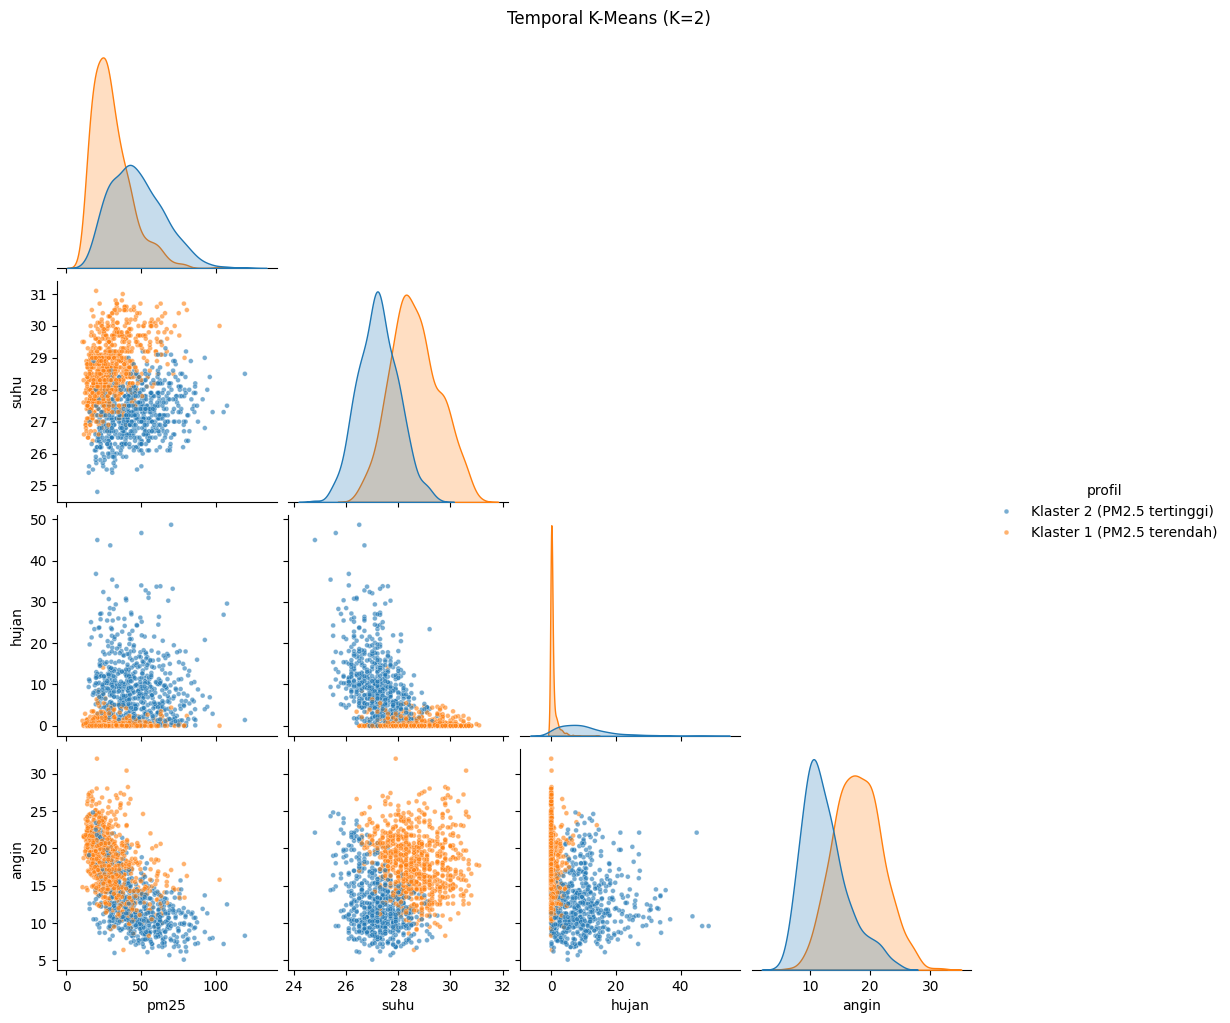

In [ ]:
# @title 2. A — Temporal K-Means (K dipilih otomatis dari silhouette)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

LOG_HUJAN = True   # hujan sangat miring ke kanan; log1p mencegah hari hujan ekstrem mendominasi jarak
FITUR = ["pm25", "suhu", "hujan", "angin"]

X = df[FITUR].copy()
if LOG_HUJAN:
    X["hujan"] = np.log1p(X["hujan"])
Xs = StandardScaler().fit_transform(X)

# --- Uji K = 2..6
baris = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xs)
    sil = silhouette_score(Xs, km.labels_)
    baris.append({"K": k, "inertia_WCSS": km.inertia_, "silhouette": sil})
    print(f"K={k} | Silhouette = {sil:.4f} | Inertia (WCSS) = {km.inertia_:.1f}")
tab_k = pd.DataFrame(baris)

K_OPT = int(tab_k.loc[tab_k["silhouette"].idxmax(), "K"])
print(f"\n>>> K optimal (silhouette tertinggi): K = {K_OPT}")
print("Catatan: silhouette sering memilih K kecil (mis. K=2, pemisahan musim). Itu sah, tapi lihat juga elbow.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tab_k["K"], tab_k["inertia_WCSS"], "o-"); ax[0].set_title("Elbow (WCSS)"); ax[0].set_xlabel("K")
ax[1].plot(tab_k["K"], tab_k["silhouette"], "o-", color="tab:green")
ax[1].axvline(K_OPT, ls="--", c="gray"); ax[1].set_title("Silhouette per K"); ax[1].set_xlabel("K")
plt.tight_layout(); plt.show()

# --- Model final
km = KMeans(n_clusters=K_OPT, n_init=20, random_state=42).fit(Xs)
df["klaster"] = km.labels_
urut = df.groupby("klaster")["pm25"].mean().sort_values().index.tolist()      # urut PM2.5 rendah -> tinggi
nama = {k: f"Klaster {i+1} (PM2.5 {'terendah' if i == 0 else 'tertinggi' if i == K_OPT-1 else 'menengah'})"
        for i, k in enumerate(urut)}
df["profil"] = df["klaster"].map(nama)

ringkas = df.groupby("profil").agg(
    n_hari=("pm25", "size"), pm25=("pm25", "mean"), suhu=("suhu", "mean"),
    hujan_mm=("hujan", "mean"), angin=("angin", "mean"),
    pct_hari_gt15=("pm25", lambda s: (s > 15).mean() * 100),
    pct_hari_gt55=("pm25", lambda s: (s > 55).mean() * 100)).round(2)
ringkas["pct_hari"] = (ringkas["n_hari"] / len(df) * 100).round(1)
print("\nRingkasan (mean) tiap klaster:"); print(ringkas.sort_values("pm25").to_string())

print("\nKomposisi bulan per klaster (% hari klaster jatuh pada bulan tsb):")
print((pd.crosstab(df["profil"], df["tanggal"].dt.month, normalize="index") * 100).round(0).to_string())

sns.pairplot(df, vars=FITUR, hue="profil", corner=True, plot_kws=dict(s=12, alpha=0.6))
plt.suptitle(f"Temporal K-Means (K={K_OPT})", y=1.02); plt.show()
df.to_csv(CLEAN / "klaster_harian.csv", index=False)

Latih: 01 Jan 2023-24 Jan 2026 (1120 hari)
Uji  : 25 Jan 2026-31 Oct 2026 (280 hari)

Baseline: klimatologi bulanan        R² =   0.244 | MAE =   8.35 | RMSE =  11.41
Baseline: musiman-naif (t-365)       R² =  -1.277 | MAE =  15.36 | RMSE =  19.79
Ridge (tren + Fourier)               R² =  -0.261 | MAE =  12.22 | RMSE =  14.73
Gradient Boosting                    R² =  -0.211 | MAE =  11.45 | RMSE =  14.43

Bulanan (n uji = 10 bulan, sampel kecil -> hati-hati menafsirkan R²):
Baseline bulanan: klimatologi        R² =   0.491 | MAE =   4.71 | RMSE =   6.35
Holt-Winters (bulanan)               R² =  -2.166 | MAE =  14.30 | RMSE =  15.85

Peringkat model harian (RMSE terkecil):
                         model     R2    MAE   RMSE
 Baseline: klimatologi bulanan  0.244  8.352 11.409
             Gradient Boosting -0.211 11.451 14.434
        Ridge (tren + Fourier) -0.261 12.225 14.730
Baseline: musiman-naif (t-365) -1.277 15.356 19.791


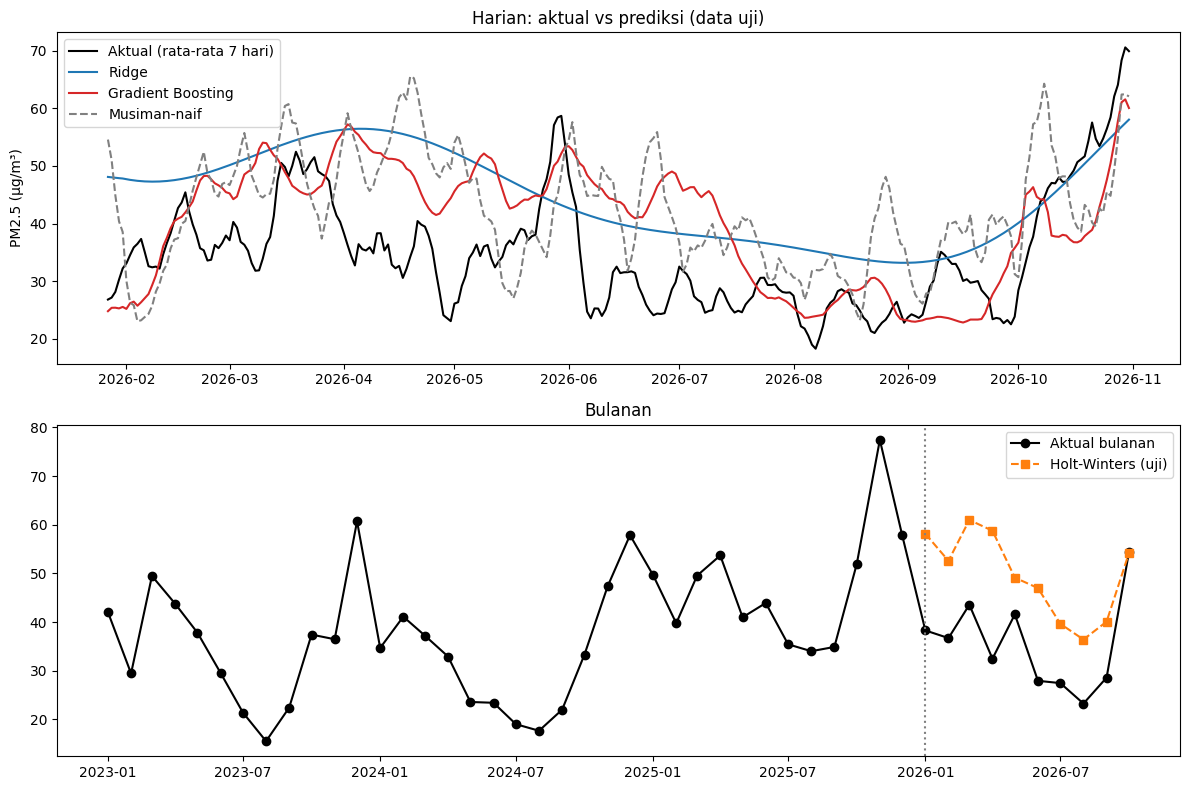

In [ ]:
# @title 3. B — Forecasting PM2.5 (split kronologis 80:20; fitur kalender/musim saja)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def metrik(y, yhat, nama):
    r2 = r2_score(y, yhat); mae = mean_absolute_error(y, yhat)
    rmse = np.sqrt(mean_squared_error(y, yhat))
    print(f"{nama:<36} R² = {r2:7.3f} | MAE = {mae:6.2f} | RMSE = {rmse:6.2f}")
    return {"model": nama, "R2": r2, "MAE": mae, "RMSE": rmse}

# ---------- B1. Harian ----------
d = df[["tanggal", "pm25"]].copy()
d["t"] = (d["tanggal"] - d["tanggal"].min()).dt.days / 365.25
doy = d["tanggal"].dt.dayofyear
FEAT = ["t"]
for h in (1, 2, 3):                                     # harmonik musiman tahunan
    d[f"sin{h}"] = np.sin(2 * np.pi * h * doy / 365.25)
    d[f"cos{h}"] = np.cos(2 * np.pi * h * doy / 365.25)
    FEAT += [f"sin{h}", f"cos{h}"]

cut = int(len(d) * 0.8)
tr, te = d.iloc[:cut].copy(), d.iloc[cut:].copy()
print(f"Latih: {tr.tanggal.min():%d %b %Y}-{tr.tanggal.max():%d %b %Y} ({len(tr)} hari)")
print(f"Uji  : {te.tanggal.min():%d %b %Y}-{te.tanggal.max():%d %b %Y} ({len(te)} hari)\n")

hasil = []
# baseline 1: klimatologi bulanan (rata-rata per bulan kalender di data latih)
clim = tr.groupby(tr["tanggal"].dt.month)["pm25"].mean()
p_clim = te["tanggal"].dt.month.map(clim)
hasil.append(metrik(te["pm25"], p_clim, "Baseline: klimatologi bulanan"))
# baseline 2: musiman-naif (nilai tanggal yang sama setahun sebelumnya)
s_all = d.set_index("tanggal")["pm25"]
p_naif = s_all.shift(365).reindex(te["tanggal"]).fillna(p_clim.set_axis(te["tanggal"])).values
hasil.append(metrik(te["pm25"], p_naif, "Baseline: musiman-naif (t-365)"))
# model 1: Ridge (tren + Fourier)
ridge = Ridge(alpha=1.0).fit(tr[FEAT], tr["pm25"]); p_ridge = ridge.predict(te[FEAT])
hasil.append(metrik(te["pm25"], p_ridge, "Ridge (tren + Fourier)"))
# model 2: Gradient Boosting (tren + Fourier). Pohon tidak bisa mengekstrapolasi tren.
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                subsample=0.8, random_state=42).fit(tr[FEAT], tr["pm25"])
p_gbr = gbr.predict(te[FEAT])
hasil.append(metrik(te["pm25"], p_gbr, "Gradient Boosting"))

# ---------- B2. Bulanan: Holt-Winters ----------
cnt = d.set_index("tanggal")["pm25"].resample("MS").count()
m = d.set_index("tanggal")["pm25"].resample("MS").mean()[cnt >= 25]        # buang bulan tidak lengkap
cm = int(len(m) * 0.8); m_tr, m_te = m.iloc[:cm], m.iloc[cm:]
hw = ExponentialSmoothing(m_tr, trend="add", damped_trend=True, seasonal="add",
                          seasonal_periods=12).fit()
p_hw = hw.forecast(len(m_te))
print(f"\nBulanan (n uji = {len(m_te)} bulan, sampel kecil -> hati-hati menafsirkan R²):")
metrik(m_te, m_tr.groupby(m_tr.index.month).mean().reindex(m_te.index.month).values, "Baseline bulanan: klimatologi")
hasil_hw = metrik(m_te, p_hw, "Holt-Winters (bulanan)")

tabel = pd.DataFrame(hasil).sort_values("RMSE"); print("\nPeringkat model harian (RMSE terkecil):"); print(tabel.round(3).to_string(index=False))

# ---------- Grafik aktual vs prediksi ----------
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
ax[0].plot(te["tanggal"], te["pm25"].rolling(7, min_periods=3).mean(), label="Aktual (rata-rata 7 hari)", c="black")
ax[0].plot(te["tanggal"], pd.Series(p_ridge, index=te.index).rolling(7, min_periods=3).mean(), label="Ridge", c="tab:blue")
ax[0].plot(te["tanggal"], pd.Series(p_gbr, index=te.index).rolling(7, min_periods=3).mean(), label="Gradient Boosting", c="tab:red")
ax[0].plot(te["tanggal"], pd.Series(p_naif, index=te.index).rolling(7, min_periods=3).mean(), label="Musiman-naif", c="gray", ls="--")
ax[0].set_title("Harian: aktual vs prediksi (data uji)"); ax[0].set_ylabel("PM2.5 (µg/m³)"); ax[0].legend()
ax[1].plot(m.index, m.values, "o-", c="black", label="Aktual bulanan")
ax[1].plot(m_te.index, p_hw.values, "s--", c="tab:orange", label="Holt-Winters (uji)")
ax[1].axvline(m_te.index[0], ls=":", c="gray"); ax[1].set_title("Bulanan"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# @title 4. C — Impak: aritmetika celah, sensitivitas, asosiasi (TANPA klaim kausal)
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score

# ---- C1. Celah RTH (aritmetika murni; sumber: seri RTH resmi Open Data Surabaya 2022-03 s/d 2025-12)
LUAS_KOTA_HA, RTH_2022, RTH_NOW, TAMAN_NOW = 33451.0, 7358.87, 7377.66, 1673.93
TAHUN_SPAN = 3.75
pct_now = RTH_NOW / LUAS_KOTA_HA * 100
gap_ha = 0.30 * LUAS_KOTA_HA - RTH_NOW
laju = (RTH_NOW - RTH_2022) / TAHUN_SPAN
print(f"RTH tercatat {pct_now:.2f}% | celah ke 30% = {gap_ha:,.0f} ha ({gap_ha / TAMAN_NOW:.1f}x seluruh taman & JH)")
print(f"Laju 2022-2025 = {laju:.1f} ha/tahun -> ~{gap_ha / laju:,.0f} tahun bila laju sama")
print("CATATAN: 30% mencakup 10% RTH privat yang tidak tercatat; angka ini mengandaikan semua tambahan RTH publik.")
print(f"Rentang RTH 2022-2025 hanya {(RTH_NOW - RTH_2022) / LUAS_KOTA_HA * 100:.2f} poin persentase "
      "-> regresi PM2.5 ~ RTH TIDAK teridentifikasi (tidak ada variasi).")

# ---- C2. Sensitivitas: jika PM2.5 turun seragam r% (dari sebab apa pun)
def sensitivitas(pm, reduksi=(0.0, 0.1, 0.2, 0.3, 0.4)):
    rows = []
    for r in reduksi:
        x = pm * (1 - r)
        rows.append({"reduksi_%": int(r * 100), "rata2": x.mean(), "hari_>15": int((x > 15).sum()),
                     "%hari_>15": (x > 15).mean() * 100, "hari_>55": int((x > 55).sum()),
                     "%hari_>55": (x > 55).mean() * 100})
    return pd.DataFrame(rows).round(1)
print("\nSensitivitas paparan terhadap reduksi seragam PM2.5:")
print(sensitivitas(df["pm25"]).to_string(index=False))
print(f"Reduksi seragam agar rata-rata <= 15 µg/m³: {(1 - 15 / df['pm25'].mean()) * 100:.0f}%")

# ---- C3. Asosiasi cuaca & musim (BUKAN sebab-akibat)
df["bulan"] = df["tanggal"].dt.month
cut = int(len(df) * 0.8); tr_, te_ = df.iloc[:cut], df.iloc[cut:]
m_musim = smf.ols("pm25 ~ C(bulan)", data=df).fit()
m_full = smf.ols("pm25 ~ angin + hujan + suhu + C(bulan)", data=df).fit()
print(f"\nR² (musim saja)        = {m_musim.rsquared:.3f}")
print(f"R² (musim + cuaca)     = {m_full.rsquared:.3f}  -> tambahan karena cuaca = {(m_full.rsquared - m_musim.rsquared) * 100:.1f} poin %")
print(m_full.params[["angin", "hujan", "suhu"]].round(3).to_string())
mt = smf.ols("pm25 ~ angin + hujan + suhu + C(bulan)", data=tr_).fit()
print(f"R² uji (latih 80% -> uji 20%) = {r2_score(te_['pm25'], mt.predict(te_)):.3f}")

# ---- C4. Pengait literatur (ISI hanya dari jurnal yang bisa disitasi)
KOEF_PERSEN_PER_PP = None   # % penurunan PM2.5 per +1 poin persentase tutupan hijau, dari literatur
if KOEF_PERSEN_PER_PP is None:
    print("\nTidak ada estimasi dampak RTH -> PM2.5: koefisien literatur belum diisi (sengaja).")
else:
    d_pp = 30 - pct_now
    print(f"\nSKENARIO HIPOTETIS: +{d_pp:.1f} pp RTH -> reduksi {KOEF_PERSEN_PER_PP * d_pp:.1f}% (asumsi literatur, bukan hasil data kita)")

RTH tercatat 22.06% | celah ke 30% = 2,658 ha (1.6x seluruh taman & JH)
Laju 2022-2025 = 5.0 ha/tahun -> ~530 tahun bila laju sama
CATATAN: 30% mencakup 10% RTH privat yang tidak tercatat; angka ini mengandaikan semua tambahan RTH publik.
Rentang RTH 2022-2025 hanya 0.06 poin persentase -> regresi PM2.5 ~ RTH TIDAK teridentifikasi (tidak ada variasi).

Sensitivitas paparan terhadap reduksi seragam PM2.5:
 reduksi_%  rata2  hari_>15  %hari_>15  hari_>55  %hari_>55
         0   37.8      1352       96.6       238       17.0
        10   34.1      1311       93.6       166       11.9
        20   30.3      1250       89.3        85        6.1
        30   26.5      1167       83.4        38        2.7
        40   22.7      1035       73.9         9        0.6
Reduksi seragam agar rata-rata <= 15 µg/m³: 60%

R² (musim saja)        = 0.339
R² (musim + cuaca)     = 0.567  -> tambahan karena cuaca = 22.8 poin %
angin   -2.150
hujan   -0.260
suhu    -0.585
R² uji (latih 80% -> uji 20%) = 0.43

---
# DRAFT NASKAH INFOGRAFIS (isi `{...}` dari output sel di atas; jangan mengarang angka)

## Section 1 — Header & judul
- **Sub-tema:** Kota Berkelanjutan: Menciptakan Ruang Hidup yang Layak serta Mewujudkan Kota yang Ramah Lingkungan
- **Pilihan judul/akronim:** **NAFAS-SBY** (*Navigasi Analitik Fluktuasi Atmosfer Surabaya*) · **HIJAU-UDARA** (*Hamparan Informasi Jernih Atmosfer Urban*) · **RUANG NAPAS** (*Surabaya 22% Hijau, Tapi Seberapa Dekat Hijau dari Napas Kita?*)
- **Tagline:** "22% hijau di atas kertas, hanya 5% taman yang dirasakan warga. Udara kota punya musim 'sesak'-nya sendiri."

## Section 2 — Problem statement
- **RTH tercatat 7.377,66 ha (22,06% dari 33.451 ha).** 61,95% adalah kawasan lindung pesisir; **taman & jalur hijau hanya 1.673,93 ha (5,0%).**
- **Stagnan:** 2022 → 2025 total RTH hanya **+18,8 ha**, taman & jalur hijau **+1,18 ha**.
- **Celah ke 30% ≈ 2.658 ha** (±1,6× seluruh taman saat ini). Dengan laju ±5 ha/tahun, butuh lebih dari 500 tahun. *(Catatan kaki: 30% termasuk 10% RTH privat yang tidak tercatat.)*
- **PM2.5 (estimasi model CAMS):** rata-rata **37,85 µg/m³**; **96,6% hari (1.356 dari 1.404)** melampaui pedoman WHO 24 jam (15 µg/m³); 17% hari (239) di atas 55 µg/m³ (ambang perlu diverifikasi).
- **Pola:** puncak Nov-Des (±51-59 µg/m³), terendah Jul-Sep (±23-27). 2025 menonjol: 40,8% hari di atas 50 µg/m³ (tahun lain 15-19%).
- **Sudut pandang resmi:** ISPU harian 2022-2024 tidak pernah "Tidak Sehat" (0 dari 1.096 hari); "Baik" hanya 20,3% (2022), 16,2% (2023), 31,7% (2024), sisanya "Sedang".

## Section 3 — Analisis Data Science
**Part A — Temporal K-Means:** "Dari {N_HARI} hari, uji K=2-6 menunjukkan silhouette tertinggi pada **K={K_OPT}** ({SIL_OPT}). Profil klaster: {klaster terendah: PM2.5 {x} µg/m³, angin {x}, hujan {x}, dominan bulan {…}} … {klaster tertinggi: …}." Fokus naratif: *kondisi harian dikelompokkan oleh musim dan angin.*

**Part B — Forecasting:** "Model {NAMA_TERBAIK} dilatih pada {tgl_latih} dan diuji pada 20% data terakhir ({tgl_uji}): **R² = {R2}, MAE = {MAE}, RMSE = {RMSE} µg/m³**, dibanding baseline musiman-naif R² = {R2_BASE}." Proyeksi menegaskan pola musiman: kewaspadaan tertinggi **Nov-Des**. Bila model tidak mengalahkan baseline, tulis: "pola musiman kuat, presisi prediksi terbatas oleh tahun anomali 2025".

## Section 4 — Solusi & teknologi *(konsep/prototipe, bukan produk yang sudah berjalan)*
- **Identitas:** **SIGAP-NAFAS** — *Sistem Informasi Gabungan Analitik PM2.5 & Atmosfer Surabaya*.
- **Workflow:** **Data Input** (Open-Meteo CAMS + cuaca, ISPU resmi, seri RTH Open Data Surabaya) → **ML Engine** (klaster kondisi harian, forecasting musiman, asosiasi cuaca) → **Actionable Recommendation**.
- **Mockup dashboard (4 panel):** (1) kalender musim rawan Nov-Des; (2) status klaster hari ini + angin; (3) RTH 2022-2025 berlabel "stagnan"; (4) kotak transparansi data.
- **Rekomendasi:** tambah stasiun pemantau PM2.5 (resmi hanya 3 stasiun); percepat tambahan taman & jalur hijau; publikasikan data RTH per kecamatan; siaga musim Nov-Des.

## Section 5 — Impak, SDGs & Transparency Note
- **Metrik (hanya yang didukung data):** "Cuaca menjelaskan tambahan {x} poin % variasi PM2.5 di luar musim (asosiasi, bukan sebab-akibat)." · "Jika PM2.5 turun {20}% dari sumber apa pun, hari >55 µg/m³ turun dari 239 menjadi {N}." · **Jangan** menulis "% efisiensi mitigasi vegetasi" kecuali koefisien literatur bersitasi terisi di sel 4 (C4).
- **SDGs:** **SDG 3** (Kehidupan Sehat) · **SDG 11** (Kota Berkelanjutan) · **SDG 13** (Penanganan Perubahan Iklim).
- **Catatan Keterbukaan Data:** "Analisis ini memakai data terbuka. Sebagian berkas Open Data Surabaya (2022-2024) sempat gagal diunduh (HTTP 500) dan dipulihkan melalui Datastore API. Tersedia seri RTH tingkat kota, namun **RTH per kecamatan tidak tersedia**; dataset taman kota hanya mencakup 38 taman di 14 kecamatan dan memuat kesalahan desimal pada sebagian bulan. Data udara resmi (SPKUA) berupa satu pengukuran per hari dari dua stasiun bergantian sehingga tidak dapat dibandingkan antar-stasiun. PM2.5 berasal dari **estimasi model CAMS (Open-Meteo)**, satu titik grid, belum divalidasi stasiun, dan tidak selaras dengan kategori ISPU resmi. Karena itu kami tidak mengklaim hubungan sebab-akibat RTH-PM2.5, melainkan menyajikan pola musiman, asosiasi cuaca, dan skenario sensitivitas."

## Checklist sebelum publikasi
- Verifikasi ambang 15 dan 55 µg/m³ ke sumber resminya.
- Cantumkan atribusi *Weather data by Open-Meteo.com*.
- Setiap angka di naskah harus bisa ditelusuri ke output sel di atas.